In [58]:
import matplotlib.pyplot as plt
from dateutil.parser import parse
import datetime
import numpy as np

In [23]:
path = r'd:\GUTO\Academia\Curso_Analise_de_Dados\Curso2026\Vazao\\'
arquivo = 'Vazoes_camaqua.txt'

with open(path + arquivo) as io:
    linhas = io.readlines()

len(linhas)

757

In [24]:
hdr = linhas[15].split(';')

for i, h in enumerate(hdr):
    print(i, h)

0 EstacaoCodigo
1 NivelConsistencia
2 Data
3 Hora
4 MediaDiaria
5 MetodoObtencaoVazoes
6 Maxima
7 Minima
8 Media
9 DiaMaxima
10 DiaMinima
11 MaximaStatus
12 MinimaStatus
13 MediaStatus
14 MediaAnual
15 MediaAnualStatus
16 Vazao01
17 Vazao02
18 Vazao03
19 Vazao04
20 Vazao05
21 Vazao06
22 Vazao07
23 Vazao08
24 Vazao09
25 Vazao10
26 Vazao11
27 Vazao12
28 Vazao13
29 Vazao14
30 Vazao15
31 Vazao16
32 Vazao17
33 Vazao18
34 Vazao19
35 Vazao20
36 Vazao21
37 Vazao22
38 Vazao23
39 Vazao24
40 Vazao25
41 Vazao26
42 Vazao27
43 Vazao28
44 Vazao29
45 Vazao30
46 Vazao31
47 Vazao01Status
48 Vazao02Status
49 Vazao03Status
50 Vazao04Status
51 Vazao05Status
52 Vazao06Status
53 Vazao07Status
54 Vazao08Status
55 Vazao09Status
56 Vazao10Status
57 Vazao11Status
58 Vazao12Status
59 Vazao13Status
60 Vazao14Status
61 Vazao15Status
62 Vazao16Status
63 Vazao17Status
64 Vazao18Status
65 Vazao19Status
66 Vazao20Status
67 Vazao21Status
68 Vazao22Status
69 Vazao23Status
70 Vazao24Status
71 Vazao25Status
72 Vazao26Statu

# Verificando se todas as linhas tem o mesmo número de campos

In [25]:
tamanho = []
for i, li in enumerate(linhas[16:]):
    liq = li.split(';')
    tamanho.append(len(liq))

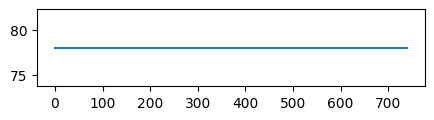

In [26]:
# tamanho[240]=77
plt.figure(figsize=(5,1))
plt.plot(tamanho)

# Prototipagem de manipulação da string

In [52]:
linha = linhas[16]
linha = linha.replace('"','').replace(',','.').split(';')

campo_data = linha[2].split('/')
mes = int(campo_data[1])
ano = int(campo_data[2])
media = float(linha[8])
tempo_dt = datetime.datetime(ano, mes, 15)

print(mes, ano, media)
print(tempo_dt, media)

4 2026 37.3618
2026-04-15 00:00:00 37.3618


In [33]:
linha[6]

'"65,8278"'

In [35]:
linha[6].replace('"','')

'65,8278'

In [36]:
linha[6].replace(',','.')

'"65.8278"'

In [38]:
float(linha[6].replace(',','.').replace('"',''))

65.8278

# Pegando os dados médios mensais

In [62]:
tempo = []
vazao_media_mensal = []
for linha in linhas[16:]:
    # linha = linhas[16]
    linha = linha.replace('"','').replace(',','.').split(';')
    
    campo_data = linha[2].split('/')
    mes = int(campo_data[1])
    ano = int(campo_data[2])
    
    campo_8 = linha[8]
    if campo_8 == '':
        media = np.nan
    else:
        media = float(campo_8)
    
    tempo_dt = datetime.datetime(ano, mes, 15)

    tempo.append(tempo_dt)
    vazao_media_mensal.append(media)

# Inspeciona o tempo para verificar se há falhas

(np.float64(12418.0), np.float64(15340.0))

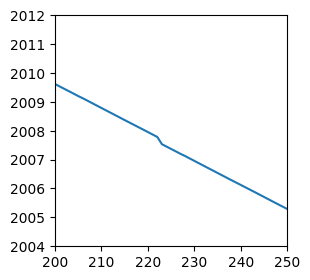

In [84]:
plt.figure(figsize=(3,3))
plt.plot(tempo)
plt.xlim(200, 250)
plt.ylim(datetime.date(2004,1,1), datetime.date(2012,1,1))

Text(0.5, 0, 'Tempo')

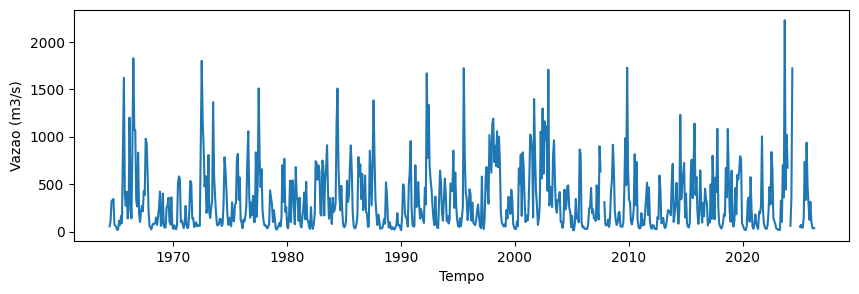

In [86]:
plt.figure(figsize=(10,3))
plt.plot(tempo, vazao_media_mensal)
plt.ylabel('Vazao (m3/s)')
plt.xlabel('Tempo')

In [87]:
tempo[-1]

datetime.datetime(1964, 5, 15, 0, 0)

# Problema no caso de desordem cronológica

In [73]:
lista_datas = [datetime.datetime(2026, 9, 29, 12),
               datetime.datetime(2026, 9, 25, 15),
               datetime.datetime(2026, 9, 30, 20)]

lista_dados = [10, 5, 15]

lista_2 = sorted(lista_datas)
lista_2

[datetime.datetime(2026, 9, 25, 15, 0),
 datetime.datetime(2026, 9, 29, 12, 0),
 datetime.datetime(2026, 9, 30, 20, 0)]

In [77]:
datas_2, dados_2 = map(list, zip(*sorted(zip(lista_datas, lista_dados))))

print(datas_2)
print(dados_2)

[datetime.datetime(2026, 9, 25, 15, 0), datetime.datetime(2026, 9, 29, 12, 0), datetime.datetime(2026, 9, 30, 20, 0)]
[5, 10, 15]


In [92]:
x = tempo[0]
x.year

2026

In [93]:
anos = np.arange(1964, 2027)

vazao_media_anual = []

for ano in anos:

    acumula_vazao = []
    for i, data_mes in enumerate(tempo):

        if data_mes.year == ano:

            acumula_vazao.append(vazao_media_mensal[i])

    vazao_media_anual.append(np.nanmean(acumula_vazao))

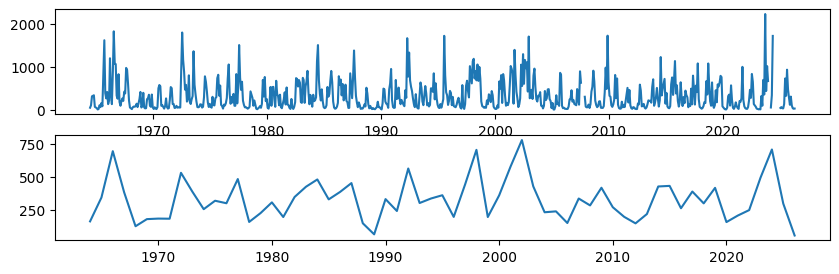

In [106]:
fig, axs = plt.subplots(2, figsize=(10,3))
axs[0].plot(tempo, vazao_media_mensal)
axs[1].plot(anos, vazao_media_anual)


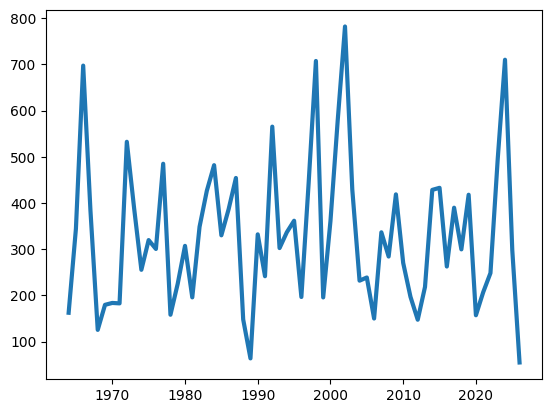

In [100]:
plt.plot(anos, vazao_media_anual, lw=3)